### rc_test5_silo

Updated calling functions for testing and implemented working freerun prediction.  

- Queensland Government, & Australian Bureau of Metreorology. (1996). SILO - Australian climate data from 1889 to yesterday [Data set]. In Using spatial interpolation to construct a comprehensive archive of Australian climate data. https://doi.org/10.1016/S1364-8152(01)00008-1    

-- Fixed plotting error of freerun prediction through stating stepsize    
-- Developed updated plots for use in Final Report  

--- Date:   June 2026

In [1]:
import urllib.request
import urllib.parse
import pandas as pd
import io
import numpy as np
import matplotlib.pyplot as plt
from great_tables import GT
import seaborn as sns
from matplotlib.colors import LogNorm  

In [2]:
def collect_data(form,lat,lon,start,finish,username,password='apirequest'):
    """
    quering and requesting data from SILO using API
    """
    params = {'format': form,
              'lat': lat,
              'lon': lon,
              'start': start,
              'finish': finish,
              'username': username,
              'password': password
             }

    api_url = 'https://www.longpaddock.qld.gov.au/cgi-bin/silo' 
    url = api_url + '/DataDrillDataset.php?' + urllib.parse.urlencode(params)
    
    with urllib.request.urlopen(url) as remote:
        data = remote.read()
        body_str = data.decode('utf-8')
        
    return pd.read_csv(io.StringIO(body_str), skiprows=31, sep=r'\s+')


In [3]:
def clean_data(df):
    """
    converting requested dataset into usable pandas dataset
    - extracting dates in format dd/mm/yyyy
    - converting columns to numeric
    - computing cumulative growing degree days using tmin, tmax and tbase (10)
    """
    df = df.drop(index=0).reset_index(drop=True)
    df['Date2'] = pd.to_datetime(df['Date2'], format='%d/%m/%Y')

    # convert columns to numeric 
    for cols in df.columns:
        if cols != 'Date2':
            try:
                df[cols] = pd.to_numeric(df[cols])
            except (ValueError, TypeError):
                pass

    # extract year, month, day
    df['Year'] = df['Date2'].dt.year
    df['Month'] = df['Date2'].dt.month
    df['Day'] = df['Date2'].dt.day
    # apply GDD calculation
    df['T.Avg'] = (df['T.Max'] + df['T.Min']) / 2
    df['GDD'] = np.where(df['T.Avg'] >= 10, df['T.Avg'] - 10, 0)
    # find cumulative growing degree days
    df['GDD.C'] = df['GDD'].cumsum()
    
    return df

def prepare_data(df, by):
    """
    preparing rainfall and cumulative growing degree set variables 
    - perform smoothing on rainfall observations through rolling window average
    -
    - normalise rainfall observations
    - extract normalised rain and gddc vectors
    """

    clean = clean_data(df)
    # smooth rain values using rolling window average
    clean['Rain.Mean'] = clean.Rain.rolling(window=180,min_periods=1).mean()

    # if wanting to retain normal time based spacing (extracts a weekly point)
    if by == "Time":
        clean_rain = clean[['Rain.Mean']].values[::7]
        clean_gddc = clean[['GDD.C']].values[::7]
    else:
        # generate regular gdd poitns every 100 units
        clean_gddc = np.arange(0, clean.GDD.sum(), 100)
        # estimate rainfall at each of these gdd points
        clean_rain = np.interp(clean_gddc, clean["GDD.C"], clean["Rain.Mean"])

    normalised_rain = []
    min_val = min(clean_rain)
    max_val = max(clean_rain)
    diff = max_val - min_val # normalise through min-max scaling
    for x in clean_rain:
        normalised_rain.append((x - min_val) / diff)
    return np.array(normalised_rain).reshape(len(clean_gddc),1), clean_gddc.reshape(len(clean_gddc),1)


In [4]:
#Testing Rain against GDDc for Merreddin 

start_date = '19710101'
end_date = '20260327'

# Merredin (10092)
# collect data with time based spacing
merre_t_data = collect_data('standard','-31.48','118.28',start_date,end_date,'email@gmail.com')
merre_t_rain, merre_tgddc = prepare_data(merre_t_data, by = "Time")

#collect data with gdd spacing
merre_data = collect_data('standard','-31.48','118.28',start_date,end_date,'email@gmail.com')
merre_rain, merre_gddc = prepare_data(merre_data, by = "")


In [5]:
class ESN:
    """
    N: number of nodes 
    d: average number of connections per node
    rho: spectral radius
    split: proportion of data to take as training  
    """
    def __init__(self, N, d, rho, input_scaling):
        self.N = N
        self.d = d
        self.rho = rho
        self.a = input_scaling


        # random, sparse, reservoir weights:
        ## connections between nodes decided by probability of d/N
        # sampling from normal distribution provides random weight values.
        Weights = np.multiply(
            np.random.binomial(size=(self.N,self.N), p=self.d/self.N, n=1),
            np.random.normal(size=(self.N,self.N)))
        
        # rescale so that rho = largest absolutel eigenvalue (maintaining echo state property)
        self.Vadj = Weights * (self.rho/np.max(np.absolute(np.linalg.eig(Weights)[0])))

        # input matrix: maps the scalar input to every node of the reservoir
        self.Vin = self.a * np.random.uniform(-1,1,size=(1, self.N))

        # bias matrix: bias added to each node's activation
        self.Vbias = np.random.uniform(-1,1,size=(1,self.N))

    def run_reservoir(self,input_data):
        """
        drive the reservoir using the input_data and return the state at every timestep
        states = (len(input_data), N)
        - comments keep track of matrix multiplications
        """
        states = np.zeros((len(input_data)+1, self.N)) # (timesteps x N)
        for i in range(1, len(input_data)+1): # start at 1 to access previous reservoir state
            states[i, :] = np.tanh(
                np.dot(states[i-1:i, :], self.Vadj) + # (1,N) x (N,N) = (1,N)
                np.dot(input_data[i-1:i], self.Vin) +  # (1,1) x (1,N) = (1,N)
                self.Vbias)
        return states[1:,:] # (timesteps x N), skip first row as it stays zero due to no input being processed.
      
      

    def train(self, train_input, train_target, washout, beta=0.01):
        """
        fit the output weights
        - remove the initial washout period from the states and target 
        - compute Vout through ridge regression
        """
        train_states = self.run_reservoir(train_input)
        # removing the washout period 
        train_states = train_states[washout:,:] 
        train_target = train_target[washout:,:]

        # using ridge regression to compute the output weights through training
        self.Vout = np.dot(
            np.linalg.pinv(np.dot(train_states.T,train_states) + beta*np.identity(self.N)), #(N,t) x (t,N) = (N,N) + (N,N)
                           np.dot(train_states.T, train_target)) #(N,t) x (t,1) = (N,1)
                           #Vout = (N,1)
                           

    def freerun(self, test_input, steps):
        """
        final attempt at a freerun prediction
        - train the reservoir computer on some testing input data 
        - following training, the readout prediction replaces the input data  
        """
        readout = self.run_reservoir(test_input) 
        freerun_states = np.zeros((steps, self.N))
        freerun_states[0,:] = readout[-1,:]
        for i in range(1, steps):
            freerun_states[i, :] = np.tanh(np.dot(freerun_states[i-1:i, :],self.Vadj) + #(1,N) x (N,N) = (1,N)
                                           np.dot(np.dot(freerun_states[i-1:i], self.Vout), self.Vin) + 
                                           self.Vbias) # the prediction replaces input_data[i-1:i]
                                           
        return np.dot(freerun_states, self.Vout)
                     

    def predict(self, test_input, test_target,washout=10):
        """
        run reservoir on test data and map states to predictions
        - remove initial washout period from states and testing input
        - compute Root Mean Squared Error of predictions 
        """
        test_states = self.run_reservoir(test_input)
        # apply trained linear readout
        predictions = np.dot(test_states, self.Vout)

        rmse = np.sqrt(((predictions[washout:,0] - test_target[washout:,0])**2).mean())

        return predictions, rmse
    


In [6]:
def splitting_data(rain,gddc,step):
    """
    function to split rainfall and cumulative growing degree days by step size
    80% of data for training, 20% for testing
    """
    # step to decide how far prediction goes
    train_size = int(len(rain) * 0.8)
    train_input = rain[:train_size-step]
    train_target = rain[step:train_size]
    test_input = rain[train_size:-step]
    test_input_x = gddc[train_size:-step]
    test_target = rain[train_size+step:]
    test_target_x = gddc[train_size+step:]

    return train_input, train_target, test_input, test_input_x, test_target, test_target_x

def plotting_data(x_values, test_actual, test_predictions, location, step, time):
    """
    function to plot the resulting predictions against the actual data
    - now adjusted to take in both gdd spacing and time spacing
    """
    plt.plot(x_values, test_actual, label = 'actual_values',color='blue',)
    plt.plot(x_values, test_predictions, label='predicted',color='green',alpha=0.6, linestyle='dashed')
    if time == True:
        plt.xlabel('Time in Days')
        title = 'Reservoir Computer Prediction of Rainfall against Days for \n' + str(location) + ' at ' + str(step) + ' Steps'
        plt.title(title)
    else:
        plt.xlabel('Cumulative Growing Degree Days (°C Days)')
        title = 'Reservoir Computer Prediction of Rainfall against Cummulative GDD. for \n' + str(location) + ' at ' + str(step) + ' Steps'
        plt.title(title)
    plt.ylabel('Standardised Rain (mm)')
    plt.title(title)
    plt.legend(['Actual Values', 'Prediction'])
    plt.savefig(f'{location}_time={time}_step={step}')
    plt.show()

def rc_for_location(esn, location, rain, gddc, step, plotting, time=False, train_washout=100, test_washout=10):
    """
    function run the ESN prediction and return RMSE  with a plot if requested.
    """
    train_input, train_target, test_input, test_input_x, test_target, test_target_x = splitting_data(rain, gddc, step)
    esn.train(train_input, train_target, washout=train_washout)
    rain_pred, rmse = esn.predict(test_input, test_target)
    if plotting == True:
        plotting_data(test_target_x[test_washout:], test_target[test_washout:], rain_pred[test_washout:], location=location, step=step, time=time)

    return rmse


def rc_with_freerun(esn, location, rain, gddc, step, freerun_steps, time=False):
   """
   function to generate freerun predictions for a particular given location and step size and produce plot
   """
   train_input, train_target, test_input, test_input_x, test_target, test_target_x = splitting_data(rain, gddc, step)
   esn.train(train_input, train_target, washout=100)
   free_run_test = esn.freerun(train_target, freerun_steps)

   plt.plot(test_input[:freerun_steps], label = 'actual_values',color='blue',)
   plt.plot(free_run_test, label='predicted',color='green',alpha=0.6, linestyle='dashed')
   if time == True:
       plt.xlabel('Time in days')
       plt.title(f'Freerun Prediction of Rainfall against days at Step {freerun_steps} for Merredin')
   else:
       plt.xlabel('Cumulative Growing Degree Days (°C Days)')
       plt.title(f'Freerun Prediction of Rainfall against Cumulative Growing Degree Days\n at Step {freerun_steps} for Merredin')

   plt.ylabel('Standardised Rain (mm)')
   plt.legend(['Actual Values', 'Freerun Prediction'])
   plt.savefig(f'Freerun_{location}_time={time}_steps={freerun_steps}')
   plt.show()

   return free_run_test

### plots with gdd spacing

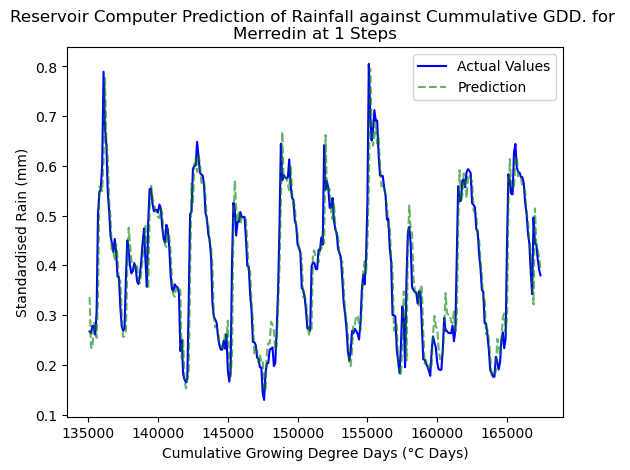

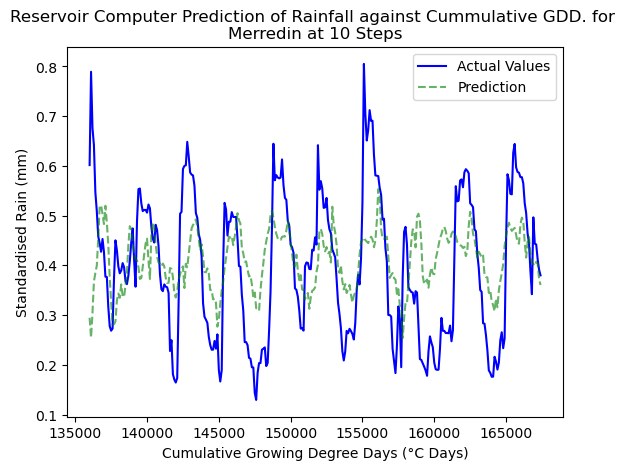

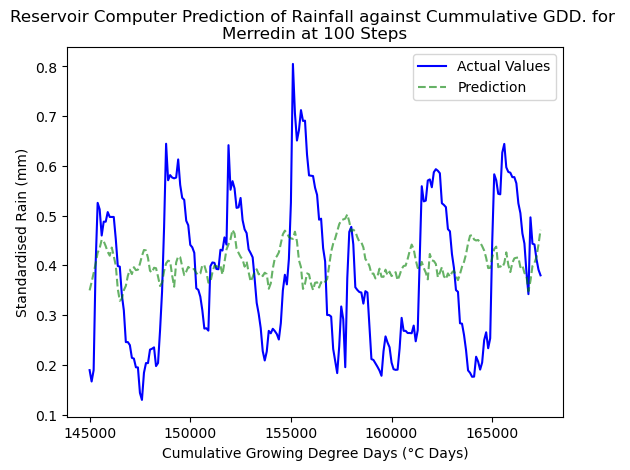

In [7]:
np.random.seed(123)
esn = ESN(300,10,0.9,1.0)

# plots for usage in final report
merre_esn_time = rc_for_location(esn,'Merredin', merre_rain, merre_gddc, step=1, plotting=True)
merre_rmse_10step = rc_for_location(esn, 'Merredin', merre_rain, merre_gddc, step=10, plotting=True)
merre_rmse_100step = rc_for_location(esn, 'Merredin', merre_rain, merre_gddc, step=100, plotting=True)


### plots with gdd spacing

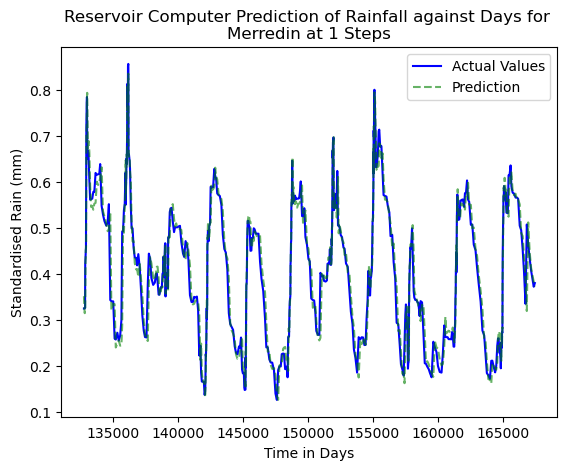

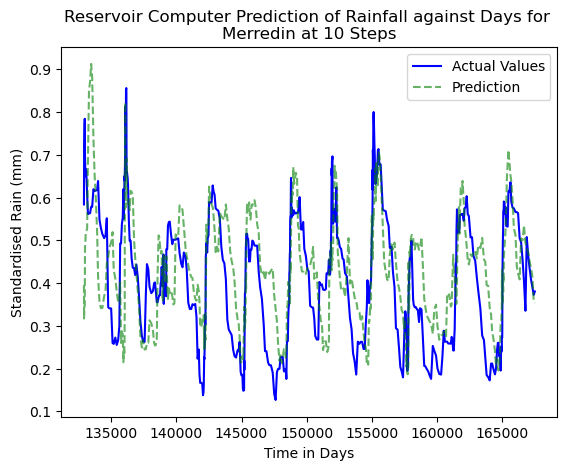

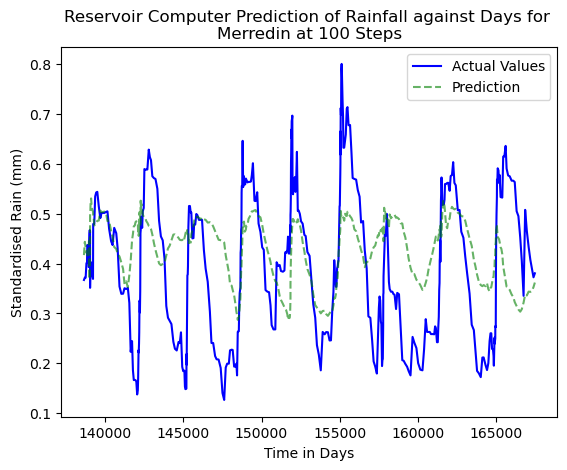

In [8]:
np.random.seed(123)

#plots for usage in final report
merre_esn_time = rc_for_location(esn,'Merredin', merre_t_rain, merre_tgddc, step=1, plotting=True, time=True)
merre_rmse_10step = rc_for_location(esn, 'Merredin', merre_t_rain, merre_tgddc, step=10, plotting=True, time=True)
merre_rmse_100step = rc_for_location(esn, 'Merredin', merre_t_rain, merre_tgddc, step=100, plotting=True, time=True)

## freerun attempts on Merredin data
-- These predictions were fairly poor, despite being interesting.  
-- None of the predictions are able to exhibit any of the periodic peaking/troughing as seen in the actual data.  

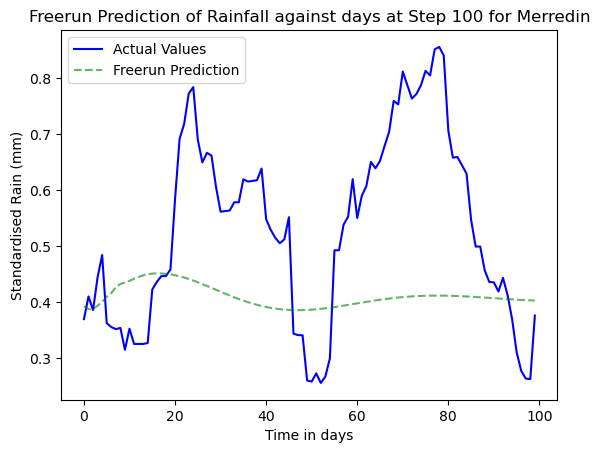

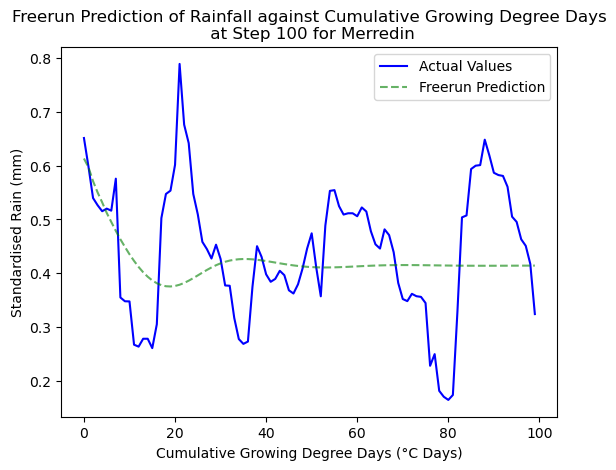

In [9]:
np.random.seed(123)

merre_freerun_time = rc_with_freerun(esn, 'Merredin', merre_t_rain, merre_tgddc, step=1, freerun_steps=100, time=True)
merre_freerun = rc_with_freerun(esn, 'Merredin', merre_rain, merre_gddc, step=1, freerun_steps=100)

## freerun attempts on toy system
-- Tests to see how the freerun attempts perform on the Logistic Map toy system.

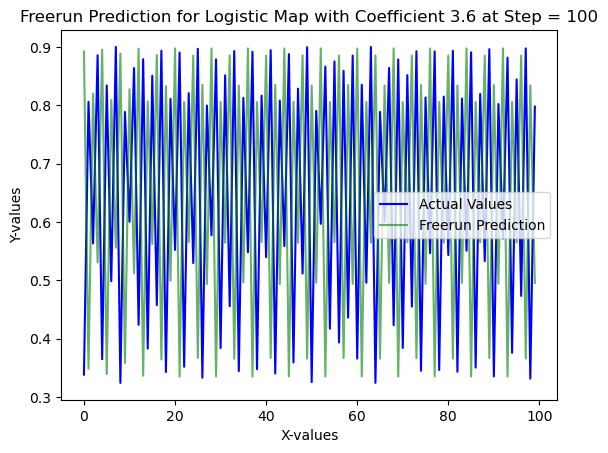

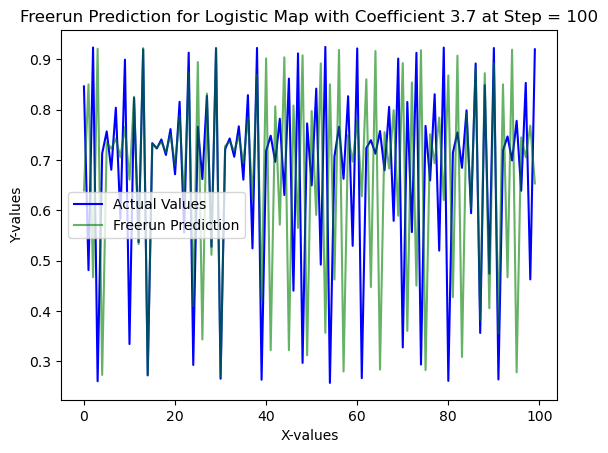

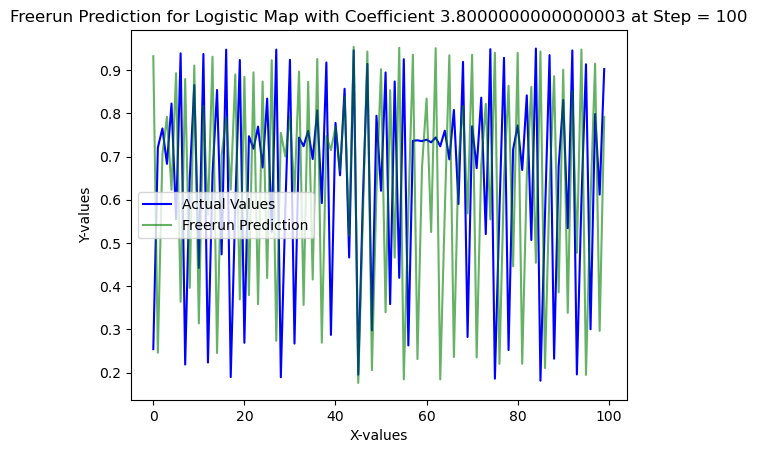

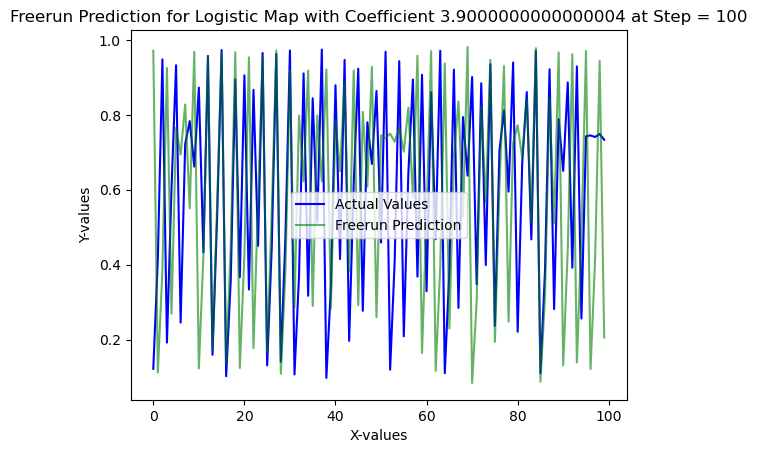

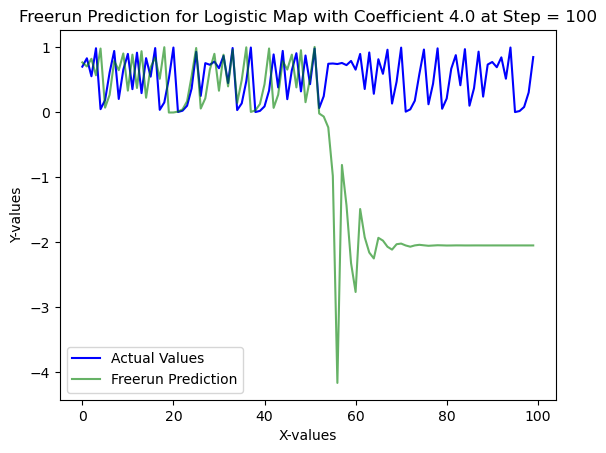

In [10]:
np.random.seed(123)

def logistic_map(r,x0,iterations):
    # r: parameter value
    #x0: starting value
    #iterations: number of vals 

    x=np.zeros(iterations)
    x[0] = x0

    for k in range(iterations-1):
        
        x[k+1] = r * x[k] * (1-x[k])
    return x

# plots to see how varying the parameters of the logistic map affects the consequent freerun prediction
for i in np.arange(3.6,4.1,0.1): # increment by 0.1
    example = logistic_map(i,0.1,1000)
    example = example.reshape(-1, 1)
    log_train_input, log_train_target, log_test_input, log_test_input_x, log_test_target, log_test_target_x = splitting_data(example, np.arange(0,len(example), dtype=int), step=1)
    esn.train(log_train_input, log_train_target, washout=100)
    log_freerun = esn.freerun(log_train_target, steps=100)
    plt.plot(log_test_target[:100], label = 'actual_values',color='blue',)
    plt.plot(log_freerun[:100], label='predicted',color='green',alpha=0.6)
    plt.title(f'Freerun Prediction for Logistic Map with Coefficient {i} at Step = 100')
    plt.xlabel('X-values')
    plt.ylabel('Y-values')
    plt.legend(['Actual Values', 'Freerun Prediction'])
    plt.show()

# while the ESN performs much more strongly for the logistic map than the sample weather data, prediction quality is ultimately not that strong
